Simulating hodgkin huxley neurons in C++
This is just a quick bit of testing, but may provide a base for an improved version of the simulator

Basic features:
Single compartment conductance based neurons
Voltage and ligand gating 
Simple conductance based synapses

Conductance based neurons:
Resting membrane potential defined in terms of membrane conductances for each ion # Nernst potentials for Na, K, Cl, and Ca, and 
Monoexponential gating defined in terms of Vhalf, Vk, theta0 theta1 sig0 k0

The fundamental principle guiding the simulation code is that we avoid any conditional (if) statements. This means we end up doing a lot of unnecessary calculations, but it allows us to run the code on a GPU which more thank makes up for it. 
I dont like the idea of current injection, or even of bias currents. I think its unphysiological to have a constant current that does not changed based on neural or external conditions.  

Extra features:
Multicompartments
ChatGPT compile python to c++
Delays
Gap junctions 
Short term plasticity
Long term calcium based plasticity 

In [1]:
from auxillaryFunctions import *

np.random.seed(0)
#neurons
#NOTE: This latest update began as me wanting to add the ability to simulate neurons and add spikers, but has changed into me trying to better initialize sims
STNchannels = np.load(r"tools\translatedSTNchannels2.npy",allow_pickle=True).item()
GPechannels = np.load(r"tools\translatedGPechannels2.npy",allow_pickle=True).item()
STNbias = -2.25
GPeBias = -.23 #-0.23

TS = 0.05  
nSTN,nGPe,nIdk = 5,10,0
nCTX,nMSN = 10,30
CTXrate,MSNrate = 3.3,2.1 #3.3,2.1
k = 4
nSTN_GPe,nGPe_GPe,nGPe_STN,nCTX_STN,nMSN_GPe = k*nSTN,k*nGPe,k*nGPe,k*nSTN,k*nGPe


STNDendriteMap = []
STNDendriteInfo = []

STNNeurons = [Neuron(i,"STN","excitatory",AISchannels=STNchannels,AISbias=STNbias,denderiteInfo=STNDendriteInfo,dendriteMap=STNDendriteMap) for i in range(nSTN)]
GPeNeurons = [Neuron(i,"GPe","inhibitory",AISchannels=GPechannels,AISbias=GPeBias) for i in range(nGPe)]
idkNeurons = [Neuron(i,"idk","inhibitory",AISchannels=GPechannels,AISbias=GPeBias) for i in range(nIdk)]

CTXSpikers = [Spiker(i,"CTX","excitatory",CTXrate,TS) for i in range(nCTX)]
MSNSpikers = [Spiker(i,"MSN","inhibitory",MSNrate,TS) for i in range(nMSN)]

neuronDict = {"STN":STNNeurons,"GPe":GPeNeurons}
spikerDict = {"CTX":CTXSpikers,"MSN":MSNSpikers}

CTXToSTNSynapses = createSynapses(CTXSpikers,STNNeurons,nCTX_STN,0.015,0.2,TS)
STNToGPeSynapses = createSynapses(STNNeurons,GPeNeurons,nSTN_GPe,0.015,4,TS) #
GPeToSTNSynapses = createSynapses(GPeNeurons,STNNeurons,nGPe_STN,0.5,4,TS)
GPeToGPeSynapses = createSynapses(GPeNeurons,GPeNeurons,nGPe_GPe,0.025,4,TS)
MSNToGPeSynapses = createSynapses(MSNSpikers,GPeNeurons,nGPe_GPe,0.02,0.2,TS)

synapseDict = {"CTXToSTN":CTXToSTNSynapses,"STNToGPe":STNToGPeSynapses,"GPeToSTN":GPeToSTNSynapses,
                "GPeToGPe":GPeToGPeSynapses,"MSNToGPe":MSNToGPeSynapses}


simData,connectionToChannelMap = genSimData(neuronDict,spikerDict,synapseDict,TS)
print(f"Total number of channels {simData["nChannels"]}")
#NOTE: 25 July 25: the STN-GPE system seems to work (no bugs or crashing), but behaviour is not as expected. Not sure why, maybe diffusion connections
#NOTE: 28 July 25: Next step is to get this working nicely on the c++ end, then try CUDA
#first I want to change how currents are accumulated so that this can be more easily parallelized
#stop using netCurrent and start using "current" with an index that matches channels to neurons
#chanToNeuron[chanId] = neuronId
#for nId,current in zip(chanToNeuron,currents): netCurrent[nId] += current
#This is basically done 28/7, just need to port to c++

#On the c++ end, we need to update a few things:
#New spiker - neuron separation
#spike and bias overwrite 

#NOTE: 5 August:
#Update c++ code for spike overwrite

#NOTE: 8 August:
#Most of the main functionality has been implemented (stimulation done recently)
#Two missing features are structural plasticity and pre synaptic short term plasticity 
#Next step is to try multithreaded c++ (but dont worry too much)
#Then implement in CUDA
#Once thats done, create a fully featured STN-GPe demo (plasticity etc.)
#Then start working on structural plasticity

#NOTE: 9 August
#First attempt at parallel execution seems to have failed.

Total number of channels 285


c:\Users\catha\source\repos\pythonCPPtesting.ipynb\auxillaryFunctions.py:48: RuntimeWarning: overflow encountered in exp
  return minOp +  (1.0-minOp)/(1.0 + np.exp((h-z)*kInv))


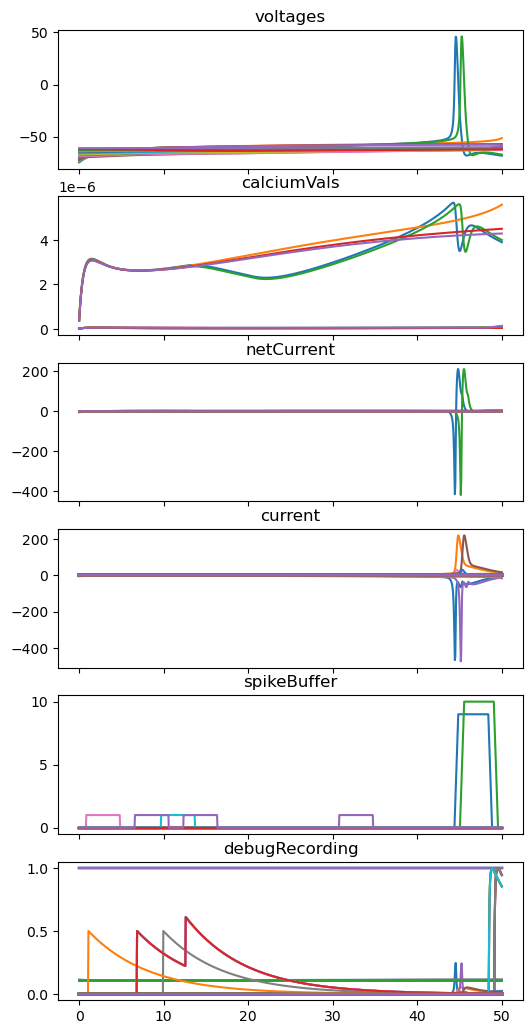

In [2]:
stimInfoSpikes = {}
# stimSynapse(stimInfoSpikes,[17,19],10,11,TS)
# stimSynapse(stimInfoSpikes,[17,20],9,11,TS)

runTime = 50
stimInfoCurrents = {} 
stimBiasCurrent(stimInfoCurrents,segmentsToStim=[0,2],currentValue=2.0,startTime=12,stopTime=20,TS=TS)

simDataPy = deepcopy(simData)
simDataPy["debugRecording"] = np.zeros_like(simDataPy["current"])
data = solveSystemStandard(simDataPy,TS,runTime,stimInfoSpikes,stimInfoCurrents,
                           recordingKeys = ["voltages","calciumVals","netCurrent","current","spikeBuffer","debugRecording"])
standardPlot(data)
#plt.plot(data["time"],data["debugRecording"][:,synapsesToStim])

Elapsed time in seconds: 2.8588367


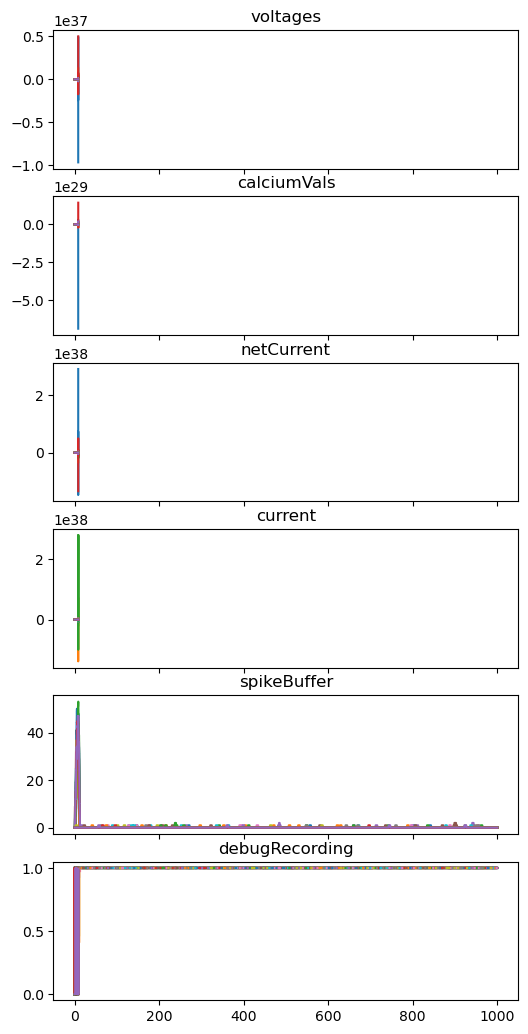

In [3]:
build_dir,configType = "build", "Debug" ##NOTE: make sure your are using correct version
moduleDir = os.path.join(build_dir, configType)
if moduleDir not in sys.path:
    sys.path.append(moduleDir)

import cathalTest

def solveSystemCpp(ac,TS,runTime,samplingInterval=2,stimInfoSpikes={}, recordingKeys = ["voltages","calciumVals","netCurrent","current"]):
    nIterations = int(runTime/TS)
    nSamples = int(np.ceil(nIterations/samplingInterval))
    spikeStimTimes,spikeStimNeurons = genSpikeStimArrays(stimInfoSpikes)
    ac["spikeStimTimes"] = spikeStimTimes
    ac["spikeStimNeurons"] = spikeStimNeurons

    biasStimTimes,biasStimSegments,biasStimValues = genBiasStimArrays(stimInfoCurrents)
    ac["biasStimTimes"] = biasStimTimes
    ac["biasStimSegments"] = biasStimSegments
    ac["biasStimValues"] = biasStimValues
    
    #data = {key:np.zeros([nSamples] + list(ac[key].shape) ) for key in recordingKeys}
    recordingData = {}
    for key in recordingKeys:
        # if len(ac[key].shape) != 1:
        #     print(f"Warning {key} shape is {ac[key].shape}")
        shape = [nSamples] + list(ac[key].shape)
        recordingData[key] = np.zeros(shape,dtype=np.float32) #np.ascontiguousarray

    tv = np.linspace(0,runTime,nSamples)

    cathalTest.solveNeuralSystem(ac,recordingData,TS,nIterations,samplingInterval)

    recordingData["time"] = tv
    return recordingData

runTime = 1000
allChannelDataCpp = deepcopy(simData)
allChannelDataCpp["debugRecording"] = np.zeros_like(simDataPy["current"])
dataCpp = solveSystemCpp(allChannelDataCpp,TS,runTime,samplingInterval=1,stimInfoSpikes=stimInfoSpikes,
                         recordingKeys = ["voltages","calciumVals","netCurrent","current","spikeBuffer","debugRecording"])
standardPlot(dataCpp)
#TODO: 07/8
#Get bias current stim working
#multithreaded c++
#port to CUDA
#2.61
#2.77


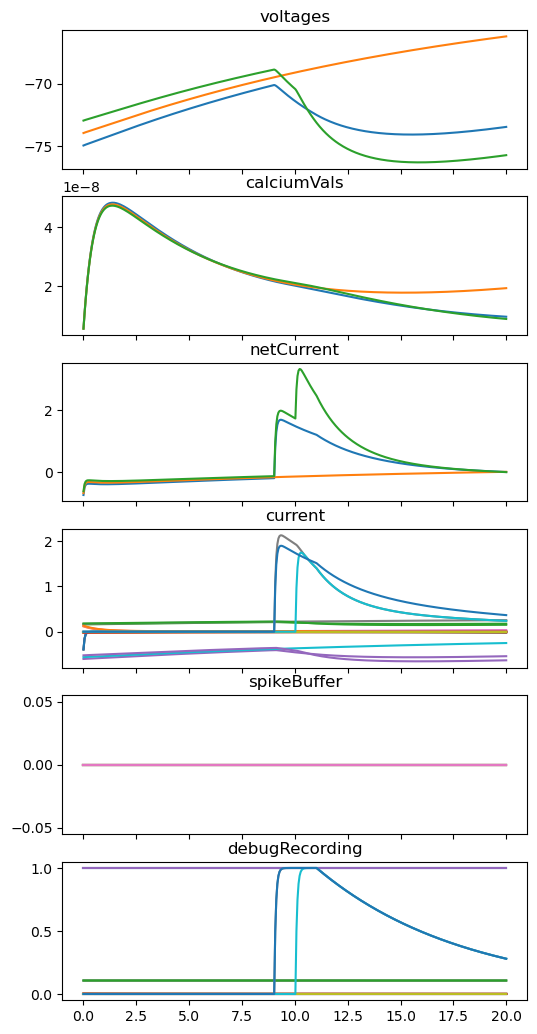

In [5]:

standardPlot(dataCpp)
#TODO: 31/7 get spike buffer recording working Done
#Then get spike overwrite working in c++
#Test diffusive connections.
#Then multithreaded c++
#Then port to CUDA

#Expression: vector subscript out of range

In [6]:
allChannelDataCpp["spikeBuffer"].shape

(2, 4)

In [10]:
allChannelDataCpp["channelPreSpiker"].shape

(6,)

ValueError: label must be scalar or have the same length as the input data, but found 21 for 6 datasets.

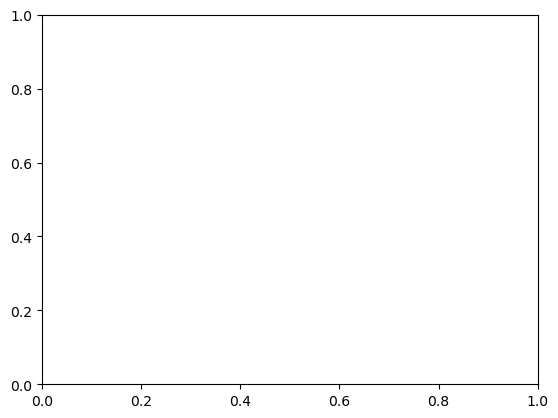

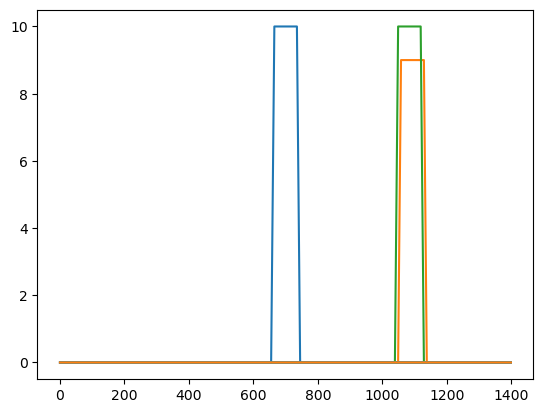

In [4]:
x = data["spikeBuffer"].sum(axis=2)
plt.plot(x);

[[False False  True ... False False False]
 [False False  True ... False False False]
 [False False  True ... False False False]
 ...
 [False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]]


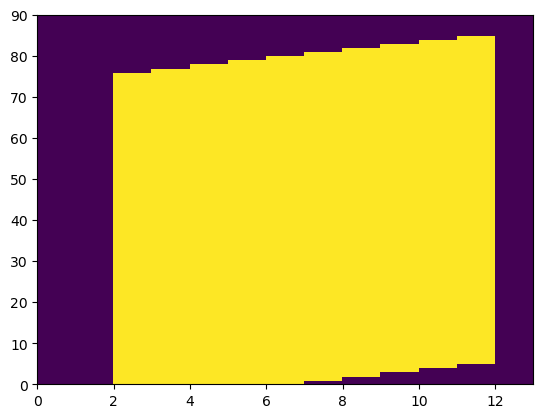

In [5]:
y = data["spikeBuffer"][660:750,0,14:27]
plt.pcolor(y)
print(y)